R_opt = 8.223 ohm   (Class-E optimum load at 4.85 V, 1.65 W)
f0    = 14.0 MHz

Chebyshev g-values (n=5, ripple=0.1 dB):
  g0 = 1.0000
  g1 = 1.1468
  g2 = 1.3712
  g3 = 1.9750
  g4 = 1.3712
  g5 = 1.1468

WB2CBA LPF (fc=15.0 MHz, 5-pole Chebyshev, 0.1 dB):
  C1 =  243.4 pF    L2 =  727.4 nH
  C3 =  419.1 pF    L4 =  727.4 nH
  C5 =  243.4 pF

L-match 8.22 ohm -> 50 ohm:
  Q_L = 2.254
  L_match (series) =  210.7 nH
  C_match (shunt)  =  512.5 pF

Current design values (for comparison):
  L_match = 285.0 nH   C_match = 1010.0 pF

L-match diagnostic (Z_in at f0 with 50 ohm load):
  correct (210.7 nH, 512.5 pF):  8.22 + j+0.00 ohm
  current (285.0 nH, 1010.0 pF):  2.41 + j+14.36 ohm
  target:                          8.22 + j0.00 ohm

=== Cascade: CORRECT L-match + WB2CBA ===
  L_match = 210.7 nH, C_match = 512.5 pF
  S11(f0) =   -28.0 dB   S21(f0) =  -0.007 dB
  Harm   Freq        S21        PA(typ)   Total      Margin   PA(cons)  Total      Margin  
  ------------------------------------

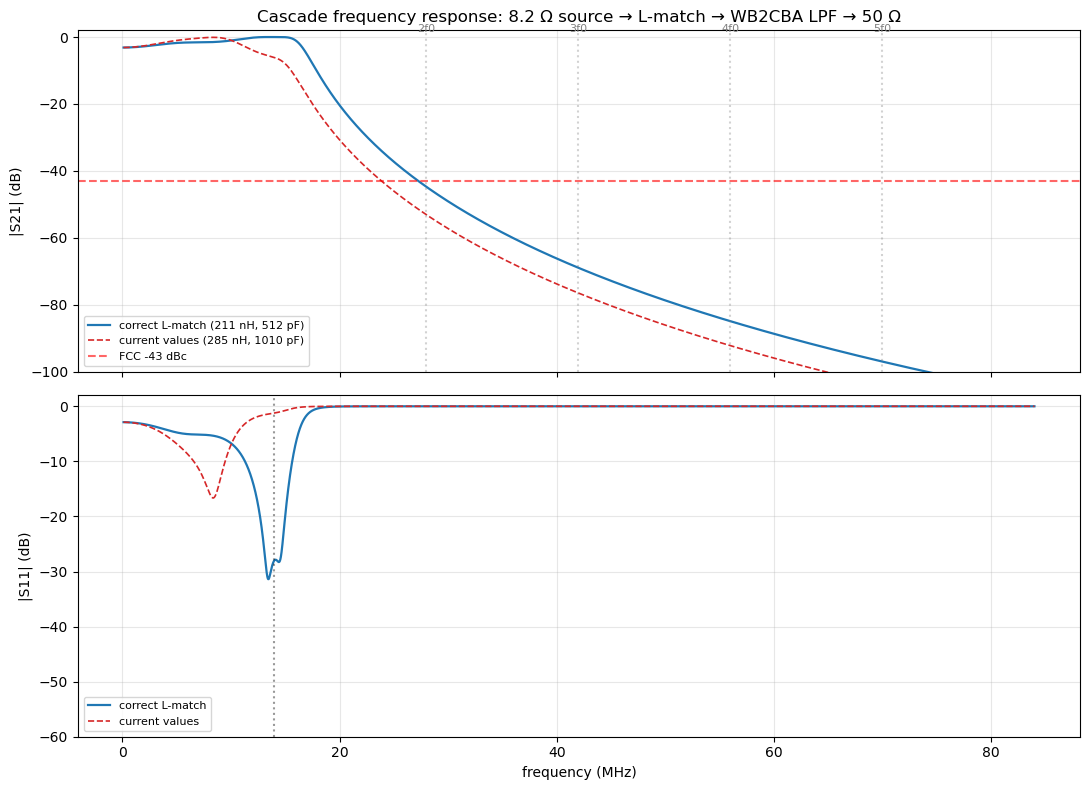


VERDICT
Correct L-match — worst margin (typical PA):        +21.8 dB
Correct L-match — worst margin (conservative PA):   +31.8 dB
Current values  — worst margin (typical PA):        +24.0 dB
Current values  — worst margin (conservative PA):   +34.0 dB

WB2CBA + correct L-match meets FCC (-43 dBc) with typical Class-E harmonics.


In [1]:
# %% [markdown]
# # WB2CBA 5-pole Chebyshev LPF + L-match (8.2 Ω → 50 Ω)
#
# **Cascade:** Class-E PA (R_opt = 8.2 Ω) → L-match → WB2CBA LPF → 50 Ω antenna
#
# Computes S11/S21 across 0–84 MHz, prints FCC margin tables with two PA
# harmonic profiles, and plots the frequency response.

# %% [markdown]
# ## Cell 1 — Constants and PA harmonic model

# %%
import numpy as np
import matplotlib.pyplot as plt

V_DD, P_out, f0 = 4.85, 1.65, 14.0e6
w0 = 2 * np.pi * f0
R_opt = 0.5768 * V_DD**2 / P_out
R_ant = 50.0

print(f"R_opt = {R_opt:.3f} ohm   (Class-E optimum load at {V_DD} V, {P_out} W)")
print(f"f0    = {f0/1e6:.1f} MHz")

def pa_harmonics_dbc(n, profile='typical'):
    if n == 1:
        return 0.0
    if profile == 'typical':
        return -10.0 - 5.0 * n     # -20, -25, -30, -35 dBc
    else:
        return -10.0 - 10.0 * n    # -30, -40, -50, -60 dBc

# %% [markdown]
# ## Cell 2 — Chebyshev g-values

# %%
def chebyshev_g_values(n, ripple_dB):
    beta = np.log(1.0 / np.tanh(ripple_dB / 17.37))
    gamma = np.sinh(beta / (2*n))
    g = np.zeros(n + 1); g[0] = 1.0
    g[1] = 2.0 * np.sin(np.pi / (2*n)) / gamma
    for k in range(2, n + 1):
        a = np.sin((2*k - 1) * np.pi / (2*n))
        b = np.sin((2*k - 3) * np.pi / (2*n))
        g[k] = 4.0 * a * b / (g[k-1] * (gamma**2 + np.sin((k-1)*np.pi/n)**2))
    return g

n_poles, ripple_dB = 5, 0.1
g = chebyshev_g_values(n_poles, ripple_dB)
print(f"\nChebyshev g-values (n={n_poles}, ripple={ripple_dB} dB):")
for i, gi in enumerate(g):
    print(f"  g{i} = {gi:.4f}")

# %% [markdown]
# ## Cell 3 — WB2CBA LPF component values (50 Ω both ports)

# %%
fc_lpf, R_LPF = 15.0e6, 50.0
C1 = g[1] / (2*np.pi*fc_lpf*R_LPF)
L2 = g[2] * R_LPF / (2*np.pi*fc_lpf)
C3 = g[3] / (2*np.pi*fc_lpf*R_LPF)
L4 = g[4] * R_LPF / (2*np.pi*fc_lpf)
C5 = g[5] / (2*np.pi*fc_lpf*R_LPF)

print(f"\nWB2CBA LPF (fc={fc_lpf/1e6:.1f} MHz, 5-pole Chebyshev, 0.1 dB):")
print(f"  C1 = {C1*1e12:6.1f} pF    L2 = {L2*1e9:6.1f} nH")
print(f"  C3 = {C3*1e12:6.1f} pF    L4 = {L4*1e9:6.1f} nH")
print(f"  C5 = {C5*1e12:6.1f} pF")

# %% [markdown]
# ## Cell 4 — L-match component values (8.2 Ω → 50 Ω)

# %%
Q_L = np.sqrt(R_ant / R_opt - 1)
L_match = Q_L * R_opt / w0
C_match = Q_L / (w0 * R_ant)

L_match_current = 285e-9
C_match_current = 1010e-12

print(f"\nL-match {R_opt:.2f} ohm -> {R_ant:.0f} ohm:")
print(f"  Q_L = {Q_L:.3f}")
print(f"  L_match (series) = {L_match*1e9:6.1f} nH")
print(f"  C_match (shunt)  = {C_match*1e12:6.1f} pF")
print(f"\nCurrent design values (for comparison):")
print(f"  L_match = {L_match_current*1e9:.1f} nH   C_match = {C_match_current*1e12:.1f} pF")

# %% [markdown]
# ## Cell 5 — ABCD matrices and S-parameter cascade

# %%
def abcd_shunt_c(C, w):
    return np.array([[1, 0], [1j*w*C, 1]], dtype=complex)

def abcd_series_l(L, w):
    return np.array([[1, 1j*w*L], [0, 1]], dtype=complex)

def s_from_abcd(M, R_in, R_out):
    A, B = M[0,0], M[0,1]
    C, D = M[1,0], M[1,1]
    d = A + B/R_out + C*R_in + D*R_in/R_out
    S11 = (A + B/R_out - C*R_in - D*R_in/R_out) / d
    S21 = 2.0 * np.sqrt(R_in/R_out) / d
    return S11, S21

def wb2cba_abcd(w):
    return (abcd_shunt_c(C1, w)
            @ abcd_series_l(L2, w)
            @ abcd_shunt_c(C3, w)
            @ abcd_series_l(L4, w)
            @ abcd_shunt_c(C5, w))

def cascade_abcd(w, Lm, Cm):
    return abcd_series_l(Lm, w) @ abcd_shunt_c(Cm, w) @ wb2cba_abcd(w)

# %% [markdown]
# ## Cell 6 — Analysis function (tables)

# %%
def analyze_cascade(Lm, Cm, label):
    w_sweep = np.linspace(2*np.pi*0.1e6, 2*np.pi*6*f0, 8000)
    f_sweep = w_sweep / (2*np.pi)
    S11, S21 = zip(*[s_from_abcd(cascade_abcd(w, Lm, Cm), R_opt, R_ant)
                     for w in w_sweep])
    S11_dB = 20*np.log10(np.maximum(np.abs(S11), 1e-30))
    S21_dB = 20*np.log10(np.maximum(np.abs(S21), 1e-30))

    idx = {n: np.argmin(np.abs(f_sweep - n*f0)) for n in range(1, 6)}
    S21_f0 = S21_dB[idx[1]]
    S21_dBc = S21_dB - S21_f0

    print(f"\n=== {label} ===")
    print(f"  L_match = {Lm*1e9:.1f} nH, C_match = {Cm*1e12:.1f} pF")
    print(f"  S11(f0) = {S11_dB[idx[1]]:+7.1f} dB   S21(f0) = {S21_dB[idx[1]]:+7.3f} dB")
    print(f"  {'Harm':<6} {'Freq':<11} {'S21':<10} {'PA(typ)':<9} "
          f"{'Total':<10} {'Margin':<8} {'PA(cons)':<9} {'Total':<10} {'Margin':<8}")
    print(f"  {'-'*90}")
    results = {}
    for n in range(2, 6):
        S21_dbc = S21_dBc[idx[n]]
        pa_typ  = pa_harmonics_dbc(n, 'typical')
        pa_cons = pa_harmonics_dbc(n, 'conservative')
        total_typ, total_cons = pa_typ + S21_dbc, pa_cons + S21_dbc
        margin_typ, margin_cons = -43 - total_typ, -43 - total_cons
        print(f"  {n}f0    {n*f0/1e6:6.1f} MHz   {S21_dbc:+7.1f} dB  "
              f"{pa_typ:6.0f} dBc  {total_typ:+7.1f} dBc  {margin_typ:+6.1f} dB   "
              f"{pa_cons:6.0f} dBc  {total_cons:+7.1f} dBc  {margin_cons:+6.1f} dB")
        results[n] = dict(S21_dbc=S21_dbc, total_typ=total_typ,
                          total_cons=total_cons, margin_typ=margin_typ,
                          margin_cons=margin_cons)
    return results

# %% [markdown]
# ## Cell 7 — L-match input impedance diagnostic

# %%
def lmatch_zin(Lm, Cm, w, R_load=50.0):
    M = abcd_series_l(Lm, w) @ abcd_shunt_c(Cm, w)
    A, B, C, D = M[0,0], M[0,1], M[1,0], M[1,1]
    return (A*R_load + B) / (C*R_load + D)

Z_correct = lmatch_zin(L_match, C_match, w0)
Z_current = lmatch_zin(L_match_current, C_match_current, w0)
print(f"\nL-match diagnostic (Z_in at f0 with 50 ohm load):")
print(f"  correct ({L_match*1e9:.1f} nH, {C_match*1e12:.1f} pF):  "
      f"{Z_correct.real:.2f} + j{Z_correct.imag:+.2f} ohm")
print(f"  current ({L_match_current*1e9:.1f} nH, {C_match_current*1e12:.1f} pF):  "
      f"{Z_current.real:.2f} + j{Z_current.imag:+.2f} ohm")
print(f"  target:                          {R_opt:.2f} + j0.00 ohm")

# %% [markdown]
# ## Cell 8 — Run both cascades (tables)

# %%
res_a = analyze_cascade(L_match, C_match, "Cascade: CORRECT L-match + WB2CBA")
res_b = analyze_cascade(L_match_current, C_match_current, "Cascade: CURRENT values + WB2CBA")

# %% [markdown]
# ## Cell 9 — Frequency response plot

# %%
w_sweep = np.linspace(2*np.pi*0.1e6, 2*np.pi*6*f0, 12000)
f_sweep = w_sweep / (2*np.pi)

def sweep_cascade(Lm, Cm):
    S11, S21 = zip(*[s_from_abcd(cascade_abcd(w, Lm, Cm), R_opt, R_ant)
                     for w in w_sweep])
    return (20*np.log10(np.maximum(np.abs(S11), 1e-30)),
            20*np.log10(np.maximum(np.abs(S21), 1e-30)))

S11_a, S21_a = sweep_cascade(L_match, C_match)
S11_b, S21_b = sweep_cascade(L_match_current, C_match_current)

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

ax = axes[0]
ax.plot(f_sweep/1e6, S21_a, 'C0',  lw=1.6,
        label=f'correct L-match ({L_match*1e9:.0f} nH, {C_match*1e12:.0f} pF)')
ax.plot(f_sweep/1e6, S21_b, 'C3--', lw=1.2,
        label=f'current values ({L_match_current*1e9:.0f} nH, {C_match_current*1e12:.0f} pF)')
for n in range(2, 6):
    ax.axvline(n*f0/1e6, color='gray', ls=':', alpha=0.35)
    ax.text(n*f0/1e6, 1, f'{n}f0', ha='center', va='bottom', fontsize=8, color='gray')
ax.axhline(-43, color='red', ls='--', alpha=0.6, label='FCC -43 dBc')
ax.set_ylabel('|S21| (dB)')
ax.set_title('Cascade frequency response: 8.2 Ω source → L-match → WB2CBA LPF → 50 Ω')
ax.set_ylim(-100, 2)
ax.legend(fontsize=8, loc='lower left')
ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(f_sweep/1e6, S11_a, 'C0',  lw=1.6, label='correct L-match')
ax.plot(f_sweep/1e6, S11_b, 'C3--', lw=1.2, label='current values')
ax.axvline(f0/1e6, color='k', ls=':', alpha=0.4)
ax.set_xlabel('frequency (MHz)')
ax.set_ylabel('|S11| (dB)')
ax.set_ylim(-60, 2)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# %% [markdown]
# ## Cell 10 — Verdict

# %%
harm = [2, 3, 4, 5]
print("\n" + "=" * 70)
print("VERDICT")
print("=" * 70)

worst_typ  = min(res_a[n]['margin_typ']  for n in harm)
worst_cons = min(res_a[n]['margin_cons'] for n in harm)
print(f"Correct L-match — worst margin (typical PA):       {worst_typ:+6.1f} dB")
print(f"Correct L-match — worst margin (conservative PA):  {worst_cons:+6.1f} dB")

worst_typ_b  = min(res_b[n]['margin_typ']  for n in harm)
worst_cons_b = min(res_b[n]['margin_cons'] for n in harm)
print(f"Current values  — worst margin (typical PA):       {worst_typ_b:+6.1f} dB")
print(f"Current values  — worst margin (conservative PA):  {worst_cons_b:+6.1f} dB")

print()
if worst_typ >= 0:
    print("WB2CBA + correct L-match meets FCC (-43 dBc) with typical Class-E harmonics.")
else:
    print("WB2CBA + correct L-match FAILS FCC with typical Class-E harmonics.")
    print("Compare JA2GQP (notches at 2f0 and 3f0) and 3Element (notch at 2f0).")